# Taller – Análisis de Componentes Principales (ACP)
## Base: *Wine* (UCI Machine Learning Repository)

**Atribución del código.** Este notebook reutiliza y adapta el código del cuaderno de clase:

> Pacheco, M. (s.f.). *Análisis Multivariado* [Repositorio de código y material de clase]. Recuperado de https://datastatistic.github.io/multivariate/
> (archivo usado: `code/python/02-mrd/Código_MRD_1_ACP.ipynb`)

**Datos.** Aeberhard, S. & Forina, M. (1992). *Wine* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5PC7J


## Justificación de la base

**(i) Contexto.** La base proviene del UCI Machine Learning Repository (donada en 1991; publicada por Forina et al., grupo PARVUS, Génova). Cada **fila es un vino** de la misma región de Italia, elaborado a partir de uno de **tres cultivares** (variedades de uva). Se midieron 13 constituyentes químicos por análisis de laboratorio. $n = 178$ vinos, sin faltantes. Como la base no trae identificador, se crea `Vino_001 … Vino_178`.

| Variable (nombre en el notebook) | Original UCI | Descripción |
|---|---|---|
| `alcohol` | Alcohol | Grado alcohólico (% vol.) |
| `ac_malico` | Malic acid | Ácido málico (acidez de origen frutal) |
| `ceniza` | Ash | Contenido de cenizas (minerales) |
| `alcal_ceniza` | Alcalinity of ash | Alcalinidad de las cenizas |
| `magnesio` | Magnesium | Magnesio |
| `fenoles_tot` | Total phenols | Fenoles totales |
| `flavonoides` | Flavanoids | Fenoles flavonoides |
| `fenoles_noflav` | Nonflavanoid phenols | Fenoles no flavonoides |
| `proantocianinas` | Proanthocyanins | Proantocianidinas (taninos condensados) |
| `int_color` | Color intensity | Intensidad de color |
| `tono` | Hue | Tonalidad del color |
| `od280_od315` | OD280/OD315 of diluted wines | Razón de absorbancias (indicador de contenido proteico/fenólico) |
| `prolina` | Proline | Prolina (aminoácido) |
| `cultivar` | class | **Cualitativa**: cultivar 1, 2 o 3 |

**(ii) Pregunta de investigación.** ¿Es posible resumir las 13 mediciones químicas de los vinos en unos pocos ejes interpretables, y esos ejes permiten diferenciar los tres cultivares de uva?

**(iii) Pertinencia del ACP.** Varias variables miden aspectos del mismo fenómeno: fenoles totales, flavonoides, proantocianidinas y OD280/OD315 miden el contenido fenólico del vino, por lo que se espera que estén fuertemente correlacionadas (redundancia). Alcohol, color y prolina también se asocian con la madurez de la uva. Esa redundancia es la que el ACP puede resumir.

## Punto 1. Carga y exploración inicial de los datos

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
# Código Propio
# a) Librerías (equivalentes en Python de las del cuaderno de clase)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Ellipse
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.stats import skew

pd.set_option("display.precision", 3)   # equivalente a options(digits = 3)
pd.set_option("display.width", 140)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 90

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
# Código Propio
# b) Importar la base, asignar identificador como nombre de fila y convertir la cualitativa a categoría
wine_raw = load_wine(as_frame=True)          # copia local de UCI Wine incluida en scikit-learn

nombres = ["alcohol", "ac_malico", "ceniza", "alcal_ceniza", "magnesio", "fenoles_tot",
           "flavonoides", "fenoles_noflav", "proantocianinas", "int_color", "tono",
           "od280_od315", "prolina"]
vinos = wine_raw.data.copy()
vinos.columns = nombres
vinos["cultivar"] = pd.Categorical(wine_raw.target.map({0: "Cultivar 1", 1: "Cultivar 2", 2: "Cultivar 3"}))
vinos.index = [f"Vino_{i+1:03d}" for i in range(len(vinos))]   # equivalente a column_to_rownames()
vinos.index.name = "id_vino"

# Se guarda el archivo para que el análisis sea reproducible desde el repositorio
vinos.to_csv("wine_uci.csv")
vinos.head()

,alcohol,ac_malico,ceniza,alcal_ceniza,magnesio,fenoles_tot,flavonoides,fenoles_noflav,proantocianinas,int_color,tono,od280_od315,prolina,cultivar
id_vino,,,,,,,,,,,,,,
Vino_001,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,Cultivar 1
Vino_002,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,Cultivar 1
Vino_003,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,Cultivar 1
Vino_004,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,Cultivar 1
Vino_005,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,Cultivar 1


In [ ]:
# Asistido por IA
# c) Dimensiones, tipo de cada variable y faltantes
print("Dimensiones:", vinos.shape)
print()
vinos.info()
faltantes = pd.DataFrame({"n_faltantes": vinos.isna().sum(),
                          "%_faltantes": vinos.isna().mean() * 100})
faltantes

Dimensiones: (178, 14)

<class 'pandas.DataFrame'>
Index: 178 entries, Vino_001 to Vino_178
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   alcohol          178 non-null    float64 
 1   ac_malico        178 non-null    float64 
 2   ceniza           178 non-null    float64 
 3   alcal_ceniza     178 non-null    float64 
 4   magnesio         178 non-null    float64 
 5   fenoles_tot      178 non-null    float64 
 6   flavonoides      178 non-null    float64 
 7   fenoles_noflav   178 non-null    float64 
 8   proantocianinas  178 non-null    float64 
 9   int_color        178 non-null    float64 
 10  tono             178 non-null    float64 
 11  od280_od315      178 non-null    float64 
 12  prolina          178 non-null    float64 
 13  cultivar         178 non-null    category
dtypes: category(1), float64(13)
memory usage: 19.7+ KB


,n_faltantes,%_faltantes
alcohol,0,0.0
ac_malico,0,0.0
ceniza,0,0.0
alcal_ceniza,0,0.0
magnesio,0,0.0
fenoles_tot,0,0.0
flavonoides,0,0.0
fenoles_noflav,0,0.0
proantocianinas,0,0.0
int_color,0,0.0


**Interpretación.** La base tiene 178 vinos y 14 columnas: 13 variables cuantitativas continuas (`float64`) y una cualitativa (`cultivar`, tipo `category`). No hay valores faltantes en ninguna variable (0 %).

**Reflexion:** Cada fila de la base de datos representa un análisis del vino especifico, cada columna representa una variable cuantitativa continua que corresponde a una característica medida en el vino. Las variables cuantitativas continuas son consideradas activas porque intervienen directamente en el calculo de los componentes principales y la varianza total. Mientras que la variable de la clase o variedad del vino es considerada suplementaria porque no participa en la construcción de los ejes.

## Punto 2. Análisis descriptivo univariado y matriz de correlaciones

In [ ]:
# Asistido por IA
# a) Estadísticos descriptivos y coeficiente de variación
num = vinos.select_dtypes(include=[np.number])
desc = num.describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
desc["CV_%"] = desc["std"] / desc["mean"] * 100
desc["asimetria"] = skew(num)
desc.round(3)

,mean,std,min,25%,50%,75%,max,CV_%,asimetria
alcohol,13.001,0.812,11.03,12.362,13.050,13.678,14.83,6.245,-0.051
ac_malico,2.336,1.117,0.74,1.602,1.865,3.082,5.80,47.816,1.031
ceniza,2.367,0.274,1.36,2.210,2.360,2.558,3.23,11.593,-0.175
alcal_ceniza,19.495,3.340,10.60,17.200,19.500,21.500,30.00,17.130,0.211
magnesio,99.742,14.282,70.00,88.000,98.000,107.000,162.00,14.319,1.089
fenoles_tot,2.295,0.626,0.98,1.742,2.355,2.800,3.88,27.269,0.086
flavonoides,2.029,0.999,0.34,1.205,2.135,2.875,5.08,49.223,0.025
fenoles_noflav,0.362,0.124,0.13,0.270,0.340,0.438,0.66,34.393,0.446
proantocianinas,1.591,0.572,0.41,1.250,1.555,1.950,3.58,35.977,0.513
int_color,5.058,2.318,1.28,3.220,4.690,6.200,13.00,45.833,0.861


**Interpretación.** Las escalas son muy distintas: `prolina` tiene media ≈ 747 y desviación ≈ 315, `magnesio` ≈ 100, mientras que `fenoles_noflav` o `tono` están por debajo de 1. Los mayores coeficientes de variación los tienen `ac_malico` (≈ 48 %), `flavonoides` (≈ 49 %) e `int_color` (≈ 46 %); los menores, `alcohol` (≈ 6 %) y `ceniza` (≈ 11 %), que son variables muy estables entre vinos.

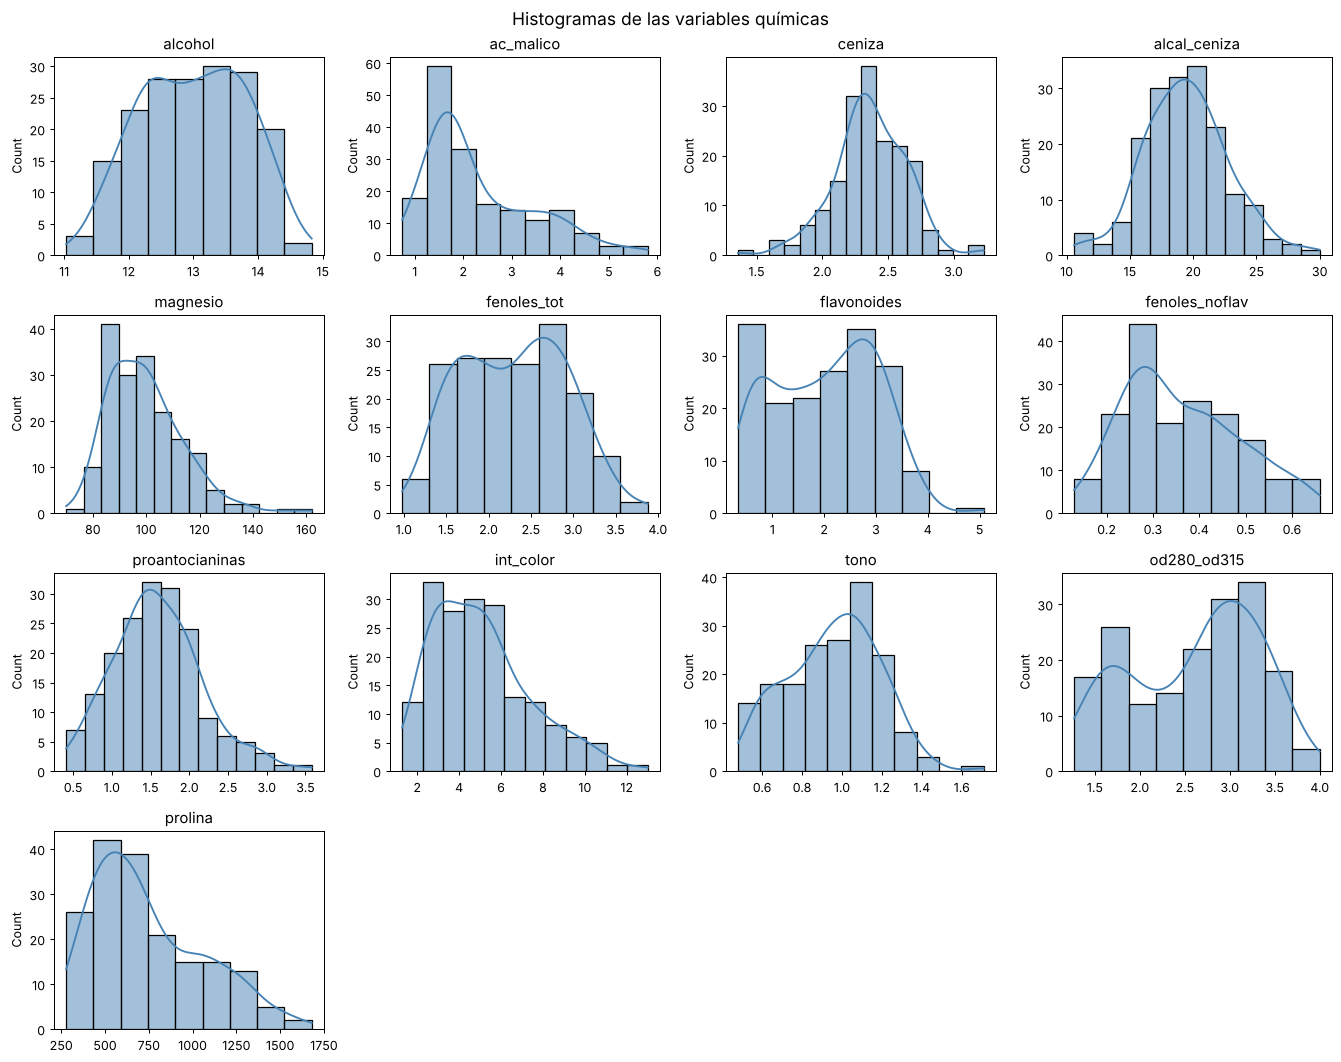

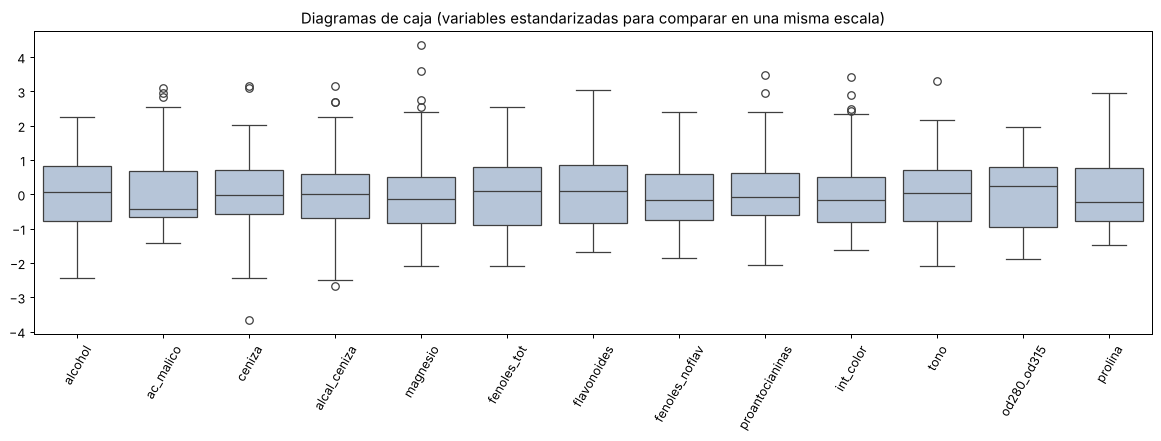

alcohol            0
ac_malico          3
ceniza             3
alcal_ceniza       4
magnesio           4
fenoles_tot        0
flavonoides        0
fenoles_noflav     0
proantocianinas    2
int_color          4
tono               1
od280_od315        0
prolina            0
Name: n_atipicos_1.5RIC, dtype: int64

In [ ]:
# Asisitido por IA
# b) Histogramas y diagramas de caja de cada variable
fig, axes = plt.subplots(4, 4, figsize=(15, 12))
for ax, v in zip(axes.flat, num.columns):
    sns.histplot(num[v], kde=True, ax=ax, color="steelblue")
    ax.set_title(v)
    ax.set_xlabel("")
for ax in axes.flat[len(num.columns):]:
    ax.axis("off")
fig.suptitle("Histogramas de las variables químicas", fontsize=14)
plt.tight_layout(); plt.show()

Zb = (num - num.mean()) / num.std()
fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=Zb, ax=ax, color="lightsteelblue")
ax.set_title("Diagramas de caja (variables estandarizadas para comparar en una misma escala)")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

# Conteo de atípicos univariados por la regla de 1.5*RIC
q1, q3 = num.quantile(.25), num.quantile(.75); ric = q3 - q1
((num < q1 - 1.5*ric) | (num > q3 + 1.5*ric)).sum().rename("n_atipicos_1.5RIC")

**Interpretación.** `ac_malico` (asimetría ≈ 1.0), `magnesio` (≈ 1.1), `int_color` (≈ 0.9) y `prolina` (≈ 0.8) tienen asimetría positiva (cola a la derecha). El resto es aproximadamente simétrico (|asimetría| < 0.5). Por la regla de 1.5·RIC hay pocos atípicos univariados: 4 en `alcal_ceniza`, `magnesio` e `int_color`, 3 en `ac_malico` y `ceniza`, 2 en `proantocianinas` y 1 en `tono`. Ninguna variable fenólica central ni `alcohol` o `prolina` tienen atípicos. Los valores extremos son plausibles químicamente (no parecen errores de digitación), por lo que se conservan.

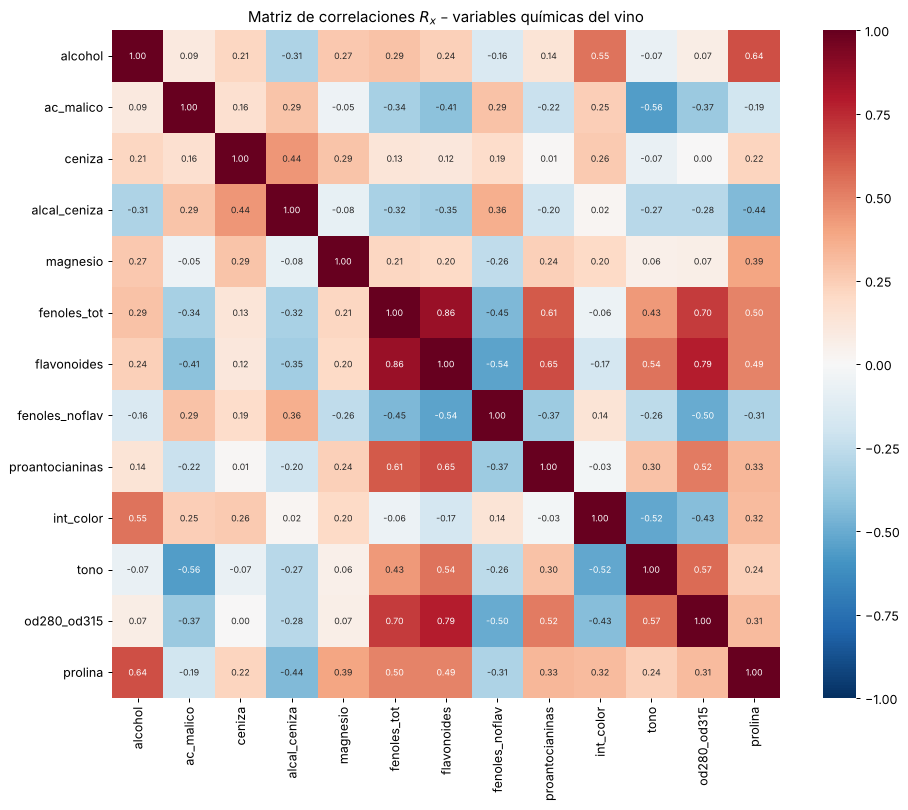

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
# Asistido por IA
# c) Matriz de correlaciones Rx y mapa de calor
Rx = num.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(Rx, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            annot_kws={"size": 7})
plt.title("Matriz de correlaciones $R_x$ – variables químicas del vino")
plt.tight_layout(); plt.show()

**Interpretación (bloques).**
- **Bloque fenólico:** `fenoles_tot`, `flavonoides`, `proantocianinas` y `od280_od315` tienen correlaciones positivas altas entre sí (≈ 0.6–0.86; flavonoides–fenoles totales ≈ 0.86). `tono` también se une a este bloque. `fenoles_noflav` y `ac_malico` se correlacionan negativamente con él.
- **Bloque alcohol/color/prolina:** `alcohol`, `int_color` y `prolina` se correlacionan positivamente (alcohol–prolina ≈ 0.64; alcohol–color ≈ 0.55).
- **Bloque mineral:** `ceniza` y `alcal_ceniza` se correlacionan moderadamente (≈ 0.44) y casi no se relacionan con el resto.

**Reflexion:** Al observar R_x hay aproximadamente 3 o 4 factores principales que agrupan  y explican la variabilidad de los atributos químicos del vino.

## Punto 3. Preprocesamiento: faltantes y estandarización

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
# Asistido por IA
# a) Casos completos (sin faltantes) – equivalente a na.omit
datos = vinos.dropna()
print("Observaciones originales:", vinos.shape[0])
print("Observaciones tras dropna():", datos.shape[0])
print("Observaciones perdidas:", vinos.shape[0] - datos.shape[0])
assert datos.shape[0] >= 100, "Se requieren al menos 100 observaciones"

Observaciones originales: 178
Observaciones tras dropna(): 178
Observaciones perdidas: 0


In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
# Asistido por IA
# b) Matriz estandarizada y ponderada: z_ij = (x_ij - media_j) / (s_j * sqrt(n-1))
X = datos.select_dtypes(include=[np.number])
n, p = X.shape
Z = X.apply(lambda x: (x - x.mean()) / (x.std(ddof=1) * np.sqrt(len(x) - 1)))
Z = Z.to_numpy()

# Equivalencia con StandardScaler: usa divisor n, por eso hay que corregir por sqrt(n/(n-1))
Z_sk = StandardScaler().fit_transform(X) * np.sqrt((n - 1) / n) / np.sqrt(n - 1)
print("¿Z coincide con StandardScaler corregido?", np.allclose(Z, Z_sk))
print(pd.DataFrame(Z[:5], index=X.index[:5], columns=X.columns).round(3))

¿Z coincide con StandardScaler corregido? True
          alcohol  ac_malico  ceniza  alcal_ceniza  magnesio  fenoles_tot  flavonoides  fenoles_noflav  proantocianinas  int_color   tono  \
id_vino                                                                                                                                     
Vino_001    0.114     -0.042   0.017        -0.088     0.143        0.061        0.078          -0.049            0.092      0.019  0.027   
Vino_002    0.018     -0.037  -0.062        -0.187     0.001        0.043        0.055          -0.062           -0.041     -0.022  0.030   
Vino_003    0.015      0.002   0.083        -0.020     0.007        0.061        0.091          -0.037            0.160      0.020  0.024   
Vino_004    0.127     -0.026   0.037        -0.061     0.070        0.187        0.110          -0.074            0.077      0.089 -0.032   
Vino_005    0.022      0.017   0.138         0.034     0.096        0.061        0.050           0.017     

In [ ]:
# Asistido por IA
# c) Verificación numérica de Z'Z = Rx
ZtZ = Z.T @ Z
print("Máxima diferencia |Z'Z - Rx| =", np.abs(ZtZ - Rx.to_numpy()).max())
print("¿Z'Z = Rx?", np.allclose(ZtZ, Rx.to_numpy()))

Máxima diferencia |Z'Z - Rx| = 1.609823385706477e-15
¿Z'Z = Rx? True


**Resultado.** Se pierden **0 observaciones** con `dropna()` (la base no tiene faltantes) y se conservan 178 ≥ 100. La matriz $Z$ cumple $Z^\top Z = R_x$ (diferencia máxima del orden de $10^{-15}$, es decir, error de redondeo).

In [ ]:
# Codigo propio
# Insumo para la reflexión: varianza de cada variable sin estandarizar y su peso en la traza de la covarianza
var_raw = X.var().sort_values(ascending=False)
pd.DataFrame({"varianza": var_raw, "%_de_la_varianza_total": var_raw / var_raw.sum() * 100}).round(3)

,varianza,%_de_la_varianza_total
prolina,99166.717,99.774
magnesio,203.989,0.205
alcal_ceniza,11.153,0.011
int_color,5.374,0.005
ac_malico,1.248,0.001
flavonoides,0.998,0.001
alcohol,0.659,0.001
od280_od315,0.504,0.001
fenoles_tot,0.392,0.000
proantocianinas,0.328,0.000


**Reflexion:** Es necesario estandarizar la base de datos de acuerdo a que las variables se encuentran en diferentes unidades de medida y ordenes de magnitud muy dispares, si no se estandarizara la matriz de covarianzas estaría dominada por la prolina o el magnesio que tienen la mayor varianza numérica; por lo tanto, el ACP reflejaría casi que únicamente la variabilidad de esas variables lo que no permitiría interpretar las otras en la base de datos.

## Punto 4. Verificación de supuestos y pertinencia del ACP

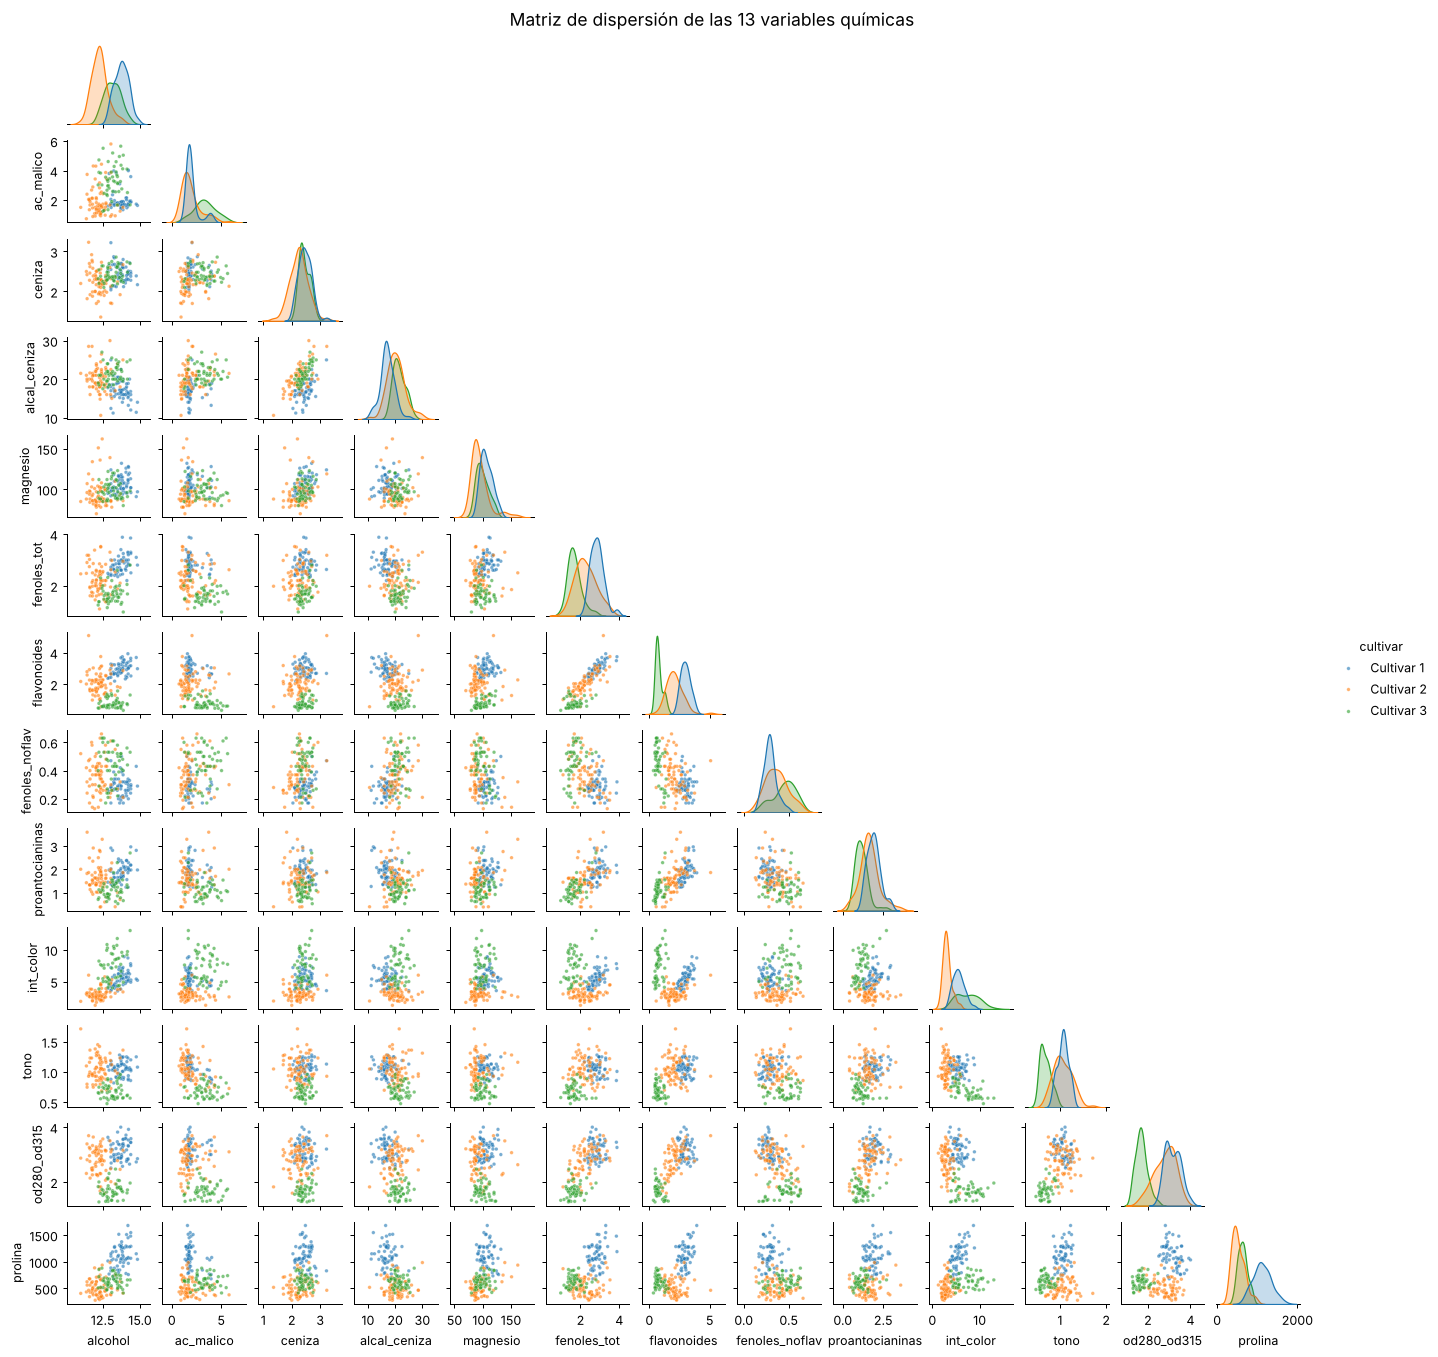

In [ ]:
# Asistido por IA
# a) Matriz de diagramas de dispersión (equivalente a pairs / GGally::ggpairs)
g = sns.pairplot(datos, vars=list(X.columns), hue="cultivar", corner=True,
                 plot_kws={"s": 8, "alpha": .6}, diag_kind="kde", height=1.15)
g.figure.suptitle("Matriz de dispersión de las 13 variables químicas", y=1.01, fontsize=14)
plt.show()

**Interpretación.** Las relaciones dentro del bloque fenólico (`fenoles_tot`, `flavonoides`, `od280_od315`, `proantocianinas`) son claramente lineales. No se observan relaciones curvas marcadas. Las variables asimétricas (`prolina`, `int_color`, `ac_malico`, `magnesio`) muestran nubes en abanico (más dispersión en valores altos). La tabla siguiente lo comprueba: al aplicar logaritmo a `prolina` o `ac_malico` la correlación de Pearson casi no cambia (0.644 → 0.637; −0.561 → −0.562) y coincide con la de Spearman (correlación de rangos). Es decir, las relaciones son monótonas y prácticamente lineales, y la transformación no aporta. Se trabaja en la escala original.

In [ ]:
# Asistido por IA
# Comprobación: ¿mejora la linealidad con log? (correlación de Pearson vs Spearman)
comp = pd.DataFrame({
    "Pearson_original": [X["prolina"].corr(X["alcohol"]), X["ac_malico"].corr(X["tono"])],
    "Pearson_log":      [np.log(X["prolina"]).corr(X["alcohol"]), np.log(X["ac_malico"]).corr(X["tono"])],
    "Spearman":         [X["prolina"].corr(X["alcohol"], method="spearman"),
                         X["ac_malico"].corr(X["tono"], method="spearman")]},
    index=["prolina-alcohol", "ac_malico-tono"])
comp.round(3)

,Pearson_original,Pearson_log,Spearman
prolina-alcohol,0.644,0.637,0.634
ac_malico-tono,-0.561,-0.562,-0.560


In [ ]:
# Asistido por IA
# b) Determinante de Rx (varianza generalizada de las variables estandarizadas)
det_Rx = np.linalg.det(Rx)
print(f"det(Rx) = {det_Rx:.6f}")

det(Rx) = 0.000469


**Interpretación.** $\det(R_x) \approx 0.00047$, muy cercano a 0 (el máximo posible, con variables incorrelacionadas, sería 1). La varianza generalizada es muy pequeña: la nube de puntos en 13 dimensiones está "aplastada" en algunas direcciones porque hay mucha redundancia lineal entre las variables. Esto justifica el ACP.

## Punto 5. Cálculo de las componentes principales "a mano" (DVS)

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
# Codigo propio
# a) DVS: Z = P D Q'
dvs = np.linalg.svd(Z, full_matrices=False)
D = np.diag(dvs[1])                    # Delta
lamb = dvs[1]**2                       # valores propios de Rx
P = dvs[0]                             # vectores propios de Z Z'
Q = dvs[2].T                           # vectores propios de Z'Z
print("Valores singulares (diag de D):", dvs[1].round(3))
print("Valores propios lambda_k:     ", lamb.round(3))
print("\nPrimeras filas de P:")
print(pd.DataFrame(P[:5, :], index=X.index[:5]).round(3))
print("\nQ (vectores propios):")
print(pd.DataFrame(Q, index=X.columns, columns=[f"CP{i+1}" for i in range(p)]).round(3))

Valores singulares (diag de D): [2.169 1.58  1.203 0.959 0.924 0.801 0.742 0.59  0.537 0.501 0.475 0.411
 0.322]
Valores propios lambda_k:      [4.706 2.497 1.446 0.919 0.853 0.642 0.551 0.348 0.289 0.251 0.226 0.169
 0.103]

Primeras filas de P:
             0      1      2      3      4      5      6      7      8      9      10     11     12
id_vino                                                                                            
Vino_001 -0.115 -0.068 -0.010 -0.017 -0.056 -0.021  0.060  0.008 -0.089 -0.153  0.071 -0.099  0.015
Vino_002 -0.076  0.016 -0.126 -0.023  0.021 -0.087  0.005  0.130  0.043 -0.024  0.023 -0.071 -0.001
Vino_003 -0.087 -0.049  0.061  0.057  0.020  0.051  0.043 -0.044  0.164 -0.017  0.045 -0.000 -0.005
Vino_004 -0.130 -0.131 -0.011  0.044  0.025  0.011 -0.039  0.082 -0.007 -0.036 -0.120  0.044  0.086
Vino_005 -0.035 -0.041  0.126 -0.032 -0.024 -0.038  0.045  0.053 -0.046  0.012  0.083  0.040  0.019

Q (vectores propios):
                   CP1    CP2 

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
# Codigo por IA
# b) Componentes principales F = Z Q
F = pd.DataFrame(Z @ Q, index=datos.index)
F.columns = [f"CP{i+1}" for i in range(F.shape[1])]
F.head()

,CP1,CP2,CP3,CP4,CP5,CP6,CP7,CP8,CP9,CP10,CP11,CP12,CP13
id_vino,,,,,,,,,,,,,
Vino_001,-0.249,-0.108,-0.012,-0.016,-0.052,-0.017,0.045,0.005,-0.048,-0.077,0.034,-4.054e-02,4.965e-03
Vino_002,-0.166,0.025,-0.152,-0.022,0.019,-0.069,0.004,0.077,0.023,-0.012,0.011,-2.910e-02,-2.726e-04
Vino_003,-0.189,-0.077,0.074,0.054,0.019,0.041,0.032,-0.026,0.088,-0.008,0.021,-4.374e-05,-1.628e-03
Vino_004,-0.282,-0.207,-0.013,0.043,0.023,0.009,-0.029,0.048,-0.004,-0.018,-0.057,1.814e-02,2.769e-02
Vino_005,-0.076,-0.065,0.152,-0.031,-0.022,-0.030,0.033,0.031,-0.024,0.006,0.039,1.624e-02,5.949e-03


In [ ]:
# Codigo propio
# c) Verificación de propiedades
print("F = P·Delta            :", np.allclose(F.to_numpy(), P @ D))
print("Q'Q = I_p              :", np.allclose(Q.T @ Q, np.eye(p)))
print(f"Suma de lambda_k = {lamb.sum():.4f}  (p = {p}) :", np.isclose(lamb.sum(), p))
var_F = F.var(ddof=1).to_numpy()
print("Var(F_k) / lambda_k (constante = 1/(n-1) =", round(1/(n-1), 6), "):", (var_F / lamb).round(6))
corF = np.corrcoef(F.T)
print("Máx |cor(F_k, F_l)|, k≠l:", np.abs(corF - np.eye(p)).max())

F = P·Delta            : True
Q'Q = I_p              : True
Suma de lambda_k = 13.0000  (p = 13) : True
Var(F_k) / lambda_k (constante = 1/(n-1) = 0.00565 ): [0.006 0.006 0.006 0.006 0.006 0.006 0.006 0.006 0.006 0.006 0.006 0.006
 0.006]
Máx |cor(F_k, F_l)|, k≠l: 1.4111175628532282e-15


In [ ]:
# Codigo propio
# d) Comparación con la descomposición espectral de cor(X)
val, vec = np.linalg.eigh(Rx)
orden = np.argsort(val)[::-1]
val, vec = val[orden], vec[:, orden]
print("lamb (DVS) vs eigen(cor):", np.allclose(lamb, val))
signos = np.sign(np.sum(Q * vec, axis=0))   # +1 si coinciden, -1 si están invertidas
print("Signo relativo de cada columna (Q vs eigen):", signos.astype(int))
print("¿|Q| = |eigen|?", np.allclose(np.abs(Q), np.abs(vec)))

lamb (DVS) vs eigen(cor): True
Signo relativo de cada columna (Q vs eigen): [ 1  1  1 -1 -1  1 -1  1 -1 -1  1  1  1]
¿|Q| = |eigen|? True


**Interpretación.** Se cumplen todas las propiedades: $F = P\Delta$, $Q^\top Q = I_{13}$, $\sum \lambda_k = 13 = p$, la varianza de cada componente es $\lambda_k/(n-1)$ (proporcional a $\lambda_k$ con constante $1/177$) y las componentes son incorrelacionadas (correlaciones del orden de $10^{-15}$).

Los valores propios de la DVS coinciden con los de `eigh(cor(X))`. Los vectores coinciden en valor absoluto, pero algunas columnas salen con **signo cambiado**: si $q_k$ es vector propio de $R_x$, también lo es $-q_k$ (cumple $R_x(-q_k) = \lambda_k(-q_k)$ y tiene norma 1). Cada algoritmo (SVD de LAPACK vs. `eigh`) elige un signo de forma arbitraria. Invertir el signo solo refleja el eje; no cambia la varianza ni la interpretación, siempre que se lean juntos loadings y coordenadas.

## Punto 6. Selección del número de componentes

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
# Codigo propio
# a) Kaiser y b) inercia
inercia = lamb / lamb.sum() * 100
inercia_acum = np.cumsum(inercia)
tabla_eig = pd.DataFrame({"v. propio": lamb, "inercia %": inercia, "iner. acum. %": inercia_acum},
                         index=[f"CP{i+1}" for i in range(p)])
print(tabla_eig.round(3))
print("\nKaiser: número de lambda_k > 1 =", (lamb > 1).sum())
print("Componentes necesarias para >= 70 %:", int(np.argmax(inercia_acum >= 70) + 1))

      v. propio  inercia %  iner. acum. %
CP1       4.706     36.199         36.199
CP2       2.497     19.207         55.406
CP3       1.446     11.124         66.530
CP4       0.919      7.069         73.599
CP5       0.853      6.563         80.162
CP6       0.642      4.936         85.098
CP7       0.551      4.239         89.337
CP8       0.348      2.681         92.018
CP9       0.289      2.222         94.240
CP10      0.251      1.930         96.170
CP11      0.226      1.737         97.907
CP12      0.169      1.298         99.205
CP13      0.103      0.795        100.000

Kaiser: número de lambda_k > 1 = 3
Componentes necesarias para >= 70 %: 4


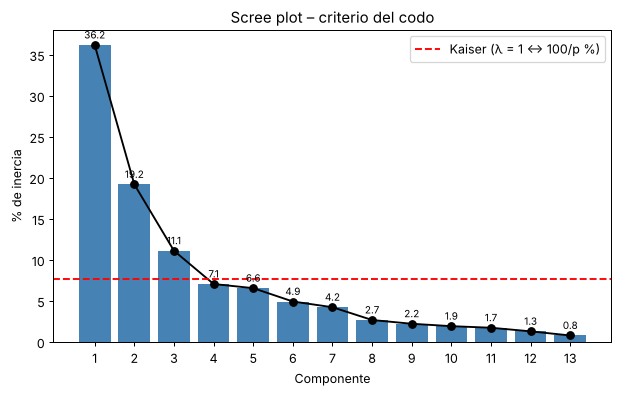

Caída entre componentes consecutivas: [16.99  8.08  4.05  0.51  1.63  0.7   1.56  0.46  0.29  0.19  0.44  0.5 ]


In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
# Codigo propio
# c) Criterio del codo (scree plot)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(range(1, p + 1), inercia, color="steelblue")
ax.plot(range(1, p + 1), inercia, "o-", color="black")
for i, v in enumerate(inercia):
    ax.text(i + 1, v + .8, f"{v:.1f}", ha="center", fontsize=8)
ax.axhline(100 / p, ls="--", color="red", label="Kaiser (λ = 1 ↔ 100/p %)")
ax.set_xticks(range(1, p + 1))
ax.set_xlabel("Componente"); ax.set_ylabel("% de inercia")
ax.set_title("Scree plot – criterio del codo"); ax.legend()
plt.show()

# Segunda diferencia de la inercia: el codo está donde la caída deja de ser fuerte
print("Caída entre componentes consecutivas:", (-np.diff(inercia)).round(2))

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
# Codigo propio
# Validación cruzada (criterio GCV) – función del profesor, como criterio adicional
def estim_ncp_gcv(X, ncp_min=0, ncp_max=None, scale=True):
    X = X.copy().astype(float)
    n, p = X.shape
    pquali = 0
    if ncp_max is None:
        ncp_max = min(n - 2, p - 1)
    else:
        ncp_max = min(n - 2, p - 1, ncp_max)
    X = X - np.nanmean(X, axis=0)
    if scale:
        X = X / np.nanstd(X, axis=0, ddof=1)
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    U, Vt, d = U[:, :ncp_max], Vt[:ncp_max, :], s[:ncp_max]
    crit = []
    for q in range(max(ncp_min, 1), ncp_max + 1):
        rec = (U[:, :q] * d[:q]) @ Vt[:q, :]
        num_ = n * p * (X - rec)
        den = (n - 1) * (p - pquali) - q * (n + p - pquali - q - 1)
        crit.append(np.nanmean((num_ / den) ** 2))
    diffs = np.diff(crit)
    ncp = (np.where(diffs > 0)[0][0] + max(ncp_min, 1)) if np.any(diffs > 0) else (np.argmin(crit) + max(ncp_min, 1))
    return {"ncp": ncp, "criterion": crit}

X_scaled = StandardScaler().fit_transform(X)
gcv = estim_ncp_gcv(X_scaled, ncp_max=8)
print(pd.DataFrame({"ncp": range(1, 9), "GCV": gcv["criterion"]}).round(4))

   ncp    GCV
0    1  0.762
1    2  0.641
2    3  0.589
3    4  0.580
4    5  0.558
5    6  0.554
6    7  0.546
7    8  0.595


In [ ]:
# Codigo propio
# d) Tabla comparativa de criterios
pd.DataFrame({
    "Criterio": ["Kaiser (λ > 1)", "Inercia acumulada ≥ 70 %", "Codo (scree plot)", "GCV (validación cruzada)"],
    "k sugerido": [int((lamb > 1).sum()), int(np.argmax(inercia_acum >= 70) + 1), 3,
                   int(np.argmin(gcv["criterion"]) + 1)],
    "Inercia acumulada con ese k (%)": [inercia_acum[2], inercia_acum[3], inercia_acum[2],
                                        inercia_acum[int(np.argmin(gcv["criterion"]))]]
}).round(1)

,Criterio,k sugerido,Inercia acumulada con ese k (%)
0,Kaiser (λ > 1),3,66.5
1,Inercia acumulada ≥ 70 %,4,73.6
2,Codo (scree plot),3,66.5
3,GCV (validación cruzada),7,89.3


**Decisión.** Kaiser y el codo sugieren **k = 3**. Con 3 componentes se explica ≈ 66.5 % de la inercia, apenas por debajo del 70 %. Llegar al 70 % exige una cuarta componente con $\lambda_4 \approx 0.92 < 1$: aporta menos que una sola variable original y su inercia (≈ 7.1 %) es casi igual a la de CP5 (≈ 6.6 %), por lo que no forma un eje estable. El GCV sugiere 7, pero su curva es casi plana desde k = 3 (0.589 → 0.546): mejora poco por cada componente extra, y CP4–CP7 tienen λ < 1. Se retienen **k = 3 componentes** (CP1 ≈ 36.2 %, CP2 ≈ 19.2 %, CP3 ≈ 11.1 %).

**Reflexion:** Cuando los criterios no coinciden se debe priorizar el porcentaje de la varianza acumulada junto con la interpretación de los datos. Si un número determinado de componentes logra retener un porcentaje satisfactorio de la inercia total y permite una interpretación química clara con respecto a la pregunta de investigación, es preferible seleccionarlas, aunque un criterio estricto sugiera añadir una dimensión más.

## Punto 7. Visualización

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
k = 3
etq = {f"CP{i+1}": f"CP{i+1} ({inercia[i]:.1f} %)" for i in range(p)}
colores = {"Cultivar 1": "#1b9e77", "Cultivar 2": "#d95f02", "Cultivar 3": "#7570b3"}
grupos = datos["cultivar"]

# Correlaciones entre componentes y variables: Rcv = cor(Z, F)
Rcv = pd.DataFrame(np.corrcoef(Z.T, F.T)[:p, p:], index=X.columns, columns=F.columns)

# cos2 y contribuciones de individuos (se usan para etiquetar solo los más relevantes)
cos2i = (F**2).div((F**2).sum(axis=1), axis=0)
ctri = (F**2).div((F**2).sum(axis=0), axis=1)

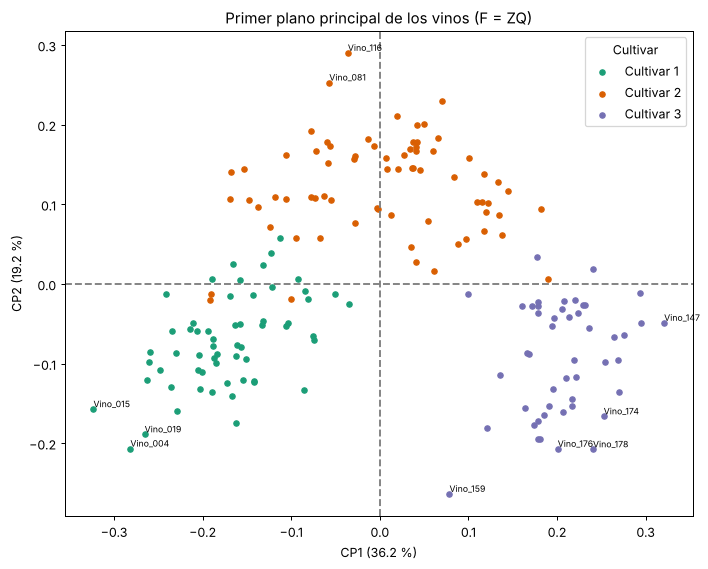

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)

# a) Primer plano principal de los individuos (CP1 vs CP2), hecho "a mano"
plt.figure(figsize=(9, 7))
for g_, col in colores.items():
    ix = grupos == g_
    plt.scatter(F.loc[ix, "CP1"], F.loc[ix, "CP2"], s=18, color=col, label=g_)
top = (ctri["CP1"] + ctri["CP2"]).nlargest(10).index      # se etiquetan los 10 más contribuyentes
for lab in top:
    plt.text(F.loc[lab, "CP1"], F.loc[lab, "CP2"], lab, fontsize=7, va="bottom")
plt.axhline(0, ls="--", color="gray"); plt.axvline(0, ls="--", color="gray")
plt.xlabel(etq["CP1"]); plt.ylabel(etq["CP2"])
plt.title("Primer plano principal de los vinos (F = ZQ)")
plt.legend(title="Cultivar"); plt.show()

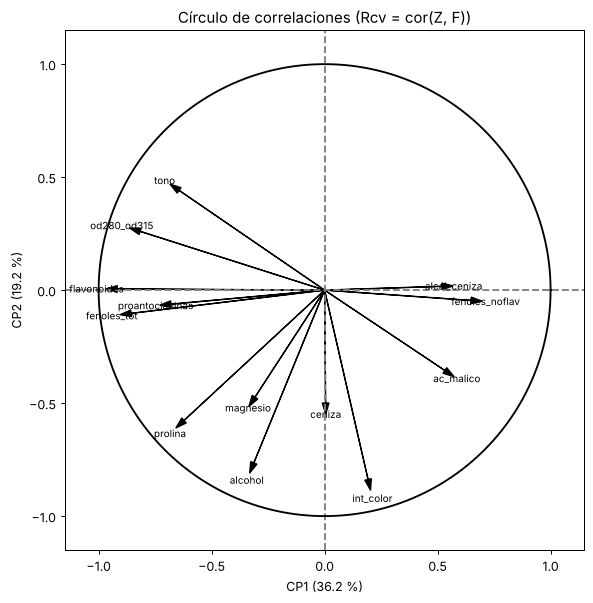

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
# Codigo propio
# a) Círculo de correlaciones construido con Rcv = cor(Z, F)
plt.figure(figsize=(7.5, 7.5))
for i, lab in enumerate(Rcv.index):
    x, y = Rcv.iloc[i, 0], Rcv.iloc[i, 1]
    plt.arrow(0, 0, x, y, head_width=0.03, head_length=0.05, fc="black", ec="black")
    plt.text(x * 1.1, y * 1.1, lab, ha="center", va="center", fontsize=8)
plt.axhline(0, ls="--", color="gray"); plt.axvline(0, ls="--", color="gray")
theta = np.linspace(0, 2 * np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), color="black")
plt.xlim(-1.15, 1.15); plt.ylim(-1.15, 1.15)
plt.gca().set_aspect("equal", adjustable="box")
plt.xlabel(etq["CP1"]); plt.ylabel(etq["CP2"])
plt.title("Círculo de correlaciones (Rcv = cor(Z, F))")
plt.show()

### b) Gráficos tipo `factoextra` (equivalentes en Python)

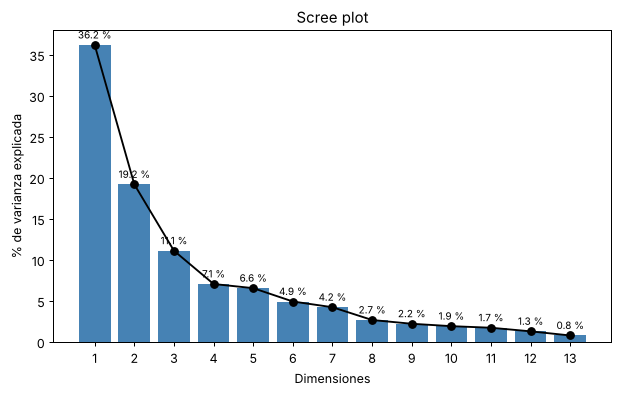

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
# Codigo propio
# Scree plot (equivalente a fviz_eig)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(range(1, p + 1), inercia, color="steelblue")
ax.plot(range(1, p + 1), inercia, "o-", color="black")
for i, v in enumerate(inercia):
    ax.text(i + 1, v + .8, f"{v:.1f} %", ha="center", fontsize=8)
ax.set_xticks(range(1, p + 1)); ax.set_xlabel("Dimensiones"); ax.set_ylabel("% de varianza explicada")
ax.set_title("Scree plot"); plt.show()

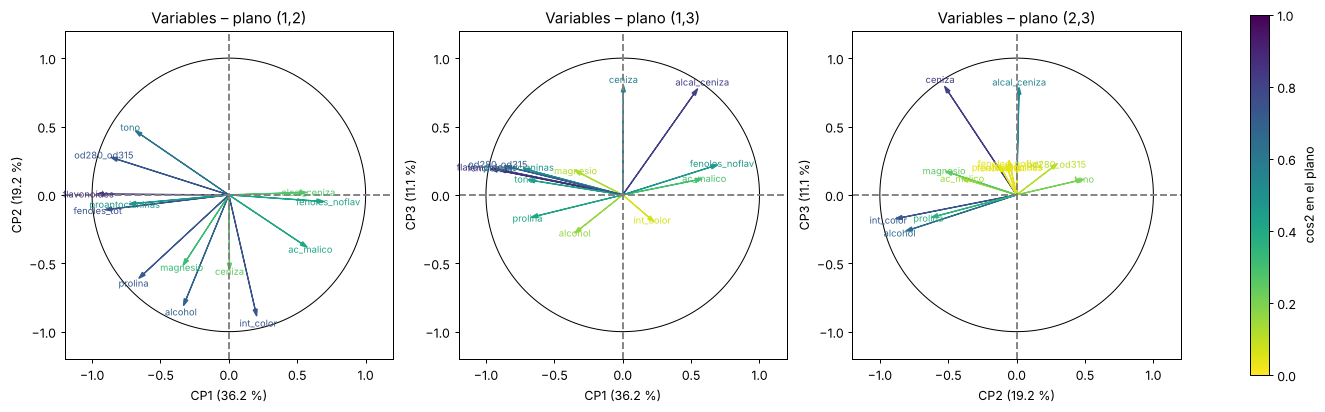

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)

# fviz_pca_var coloreado por cos2 en los planos (1,2), (1,3) y (2,3)
cos2v = Rcv**2

def circulo_cos2(a, b, ax):
    col = cos2v[a] + cos2v[b]
    norm = plt.Normalize(vmin=0, vmax=1)
    for i, lab in enumerate(Rcv.index):
        x, y = Rcv[a].iloc[i], Rcv[b].iloc[i]
        c = plt.cm.viridis_r(norm(col.iloc[i]))
        ax.arrow(0, 0, x, y, head_width=0.03, head_length=0.05, fc=c, ec=c)
        ax.text(x * 1.12, y * 1.12, lab, fontsize=7.5, ha="center", va="center", color=c)
    t = np.linspace(0, 2 * np.pi, 200); ax.plot(np.cos(t), np.sin(t), color="black", lw=.8)
    ax.axhline(0, ls="--", color="gray"); ax.axvline(0, ls="--", color="gray")
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal")
    ax.set_xlabel(etq[a]); ax.set_ylabel(etq[b]); ax.set_title(f"Variables – plano ({a[2:]},{b[2:]})")
    return plt.cm.ScalarMappable(cmap="viridis_r", norm=norm)

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
for ax, (a, b) in zip(axes, [("CP1", "CP2"), ("CP1", "CP3"), ("CP2", "CP3")]):
    sm = circulo_cos2(a, b, ax)
fig.colorbar(sm, ax=axes, label="cos2 en el plano", shrink=.8)
plt.show()

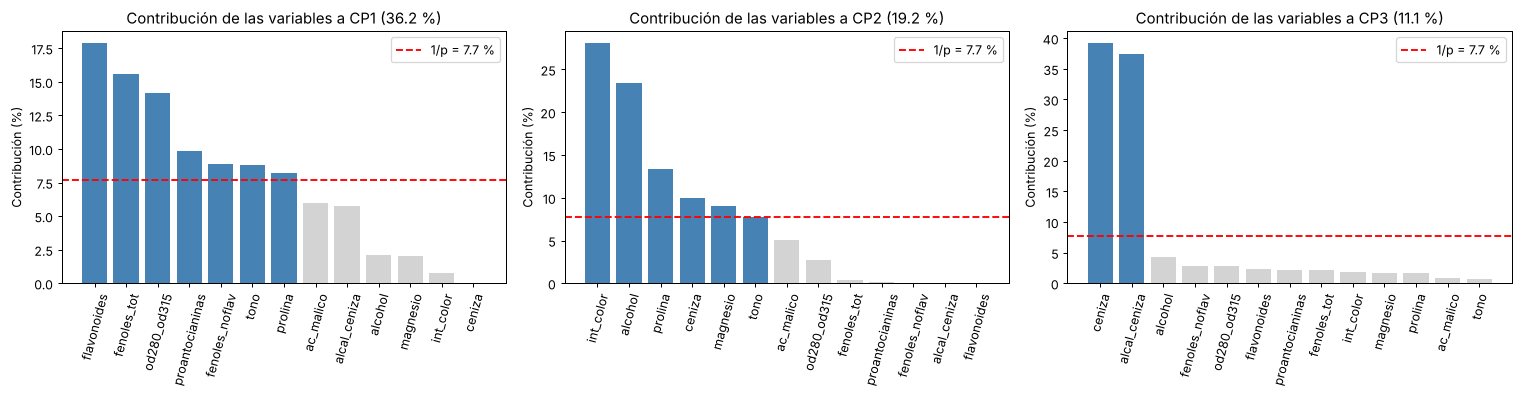

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)

# fviz_contrib para las componentes retenidas
ctrv = (Rcv**2).div((Rcv**2).sum(axis=0), axis=1) * 100
ref = 100 / p
fig, axes = plt.subplots(1, k, figsize=(17, 4.5))
for j, ax in enumerate(axes):
    c = f"CP{j+1}"
    s = ctrv[c].sort_values(ascending=False)
    ax.bar(s.index, s.values, color=["steelblue" if v > ref else "lightgray" for v in s.values])
    ax.axhline(ref, color="red", ls="--", label=f"1/p = {ref:.1f} %")
    ax.set_title(f"Contribución de las variables a {etq[c]}")
    ax.set_ylabel("Contribución (%)"); ax.tick_params(axis="x", rotation=75); ax.legend()
plt.tight_layout(); plt.show()

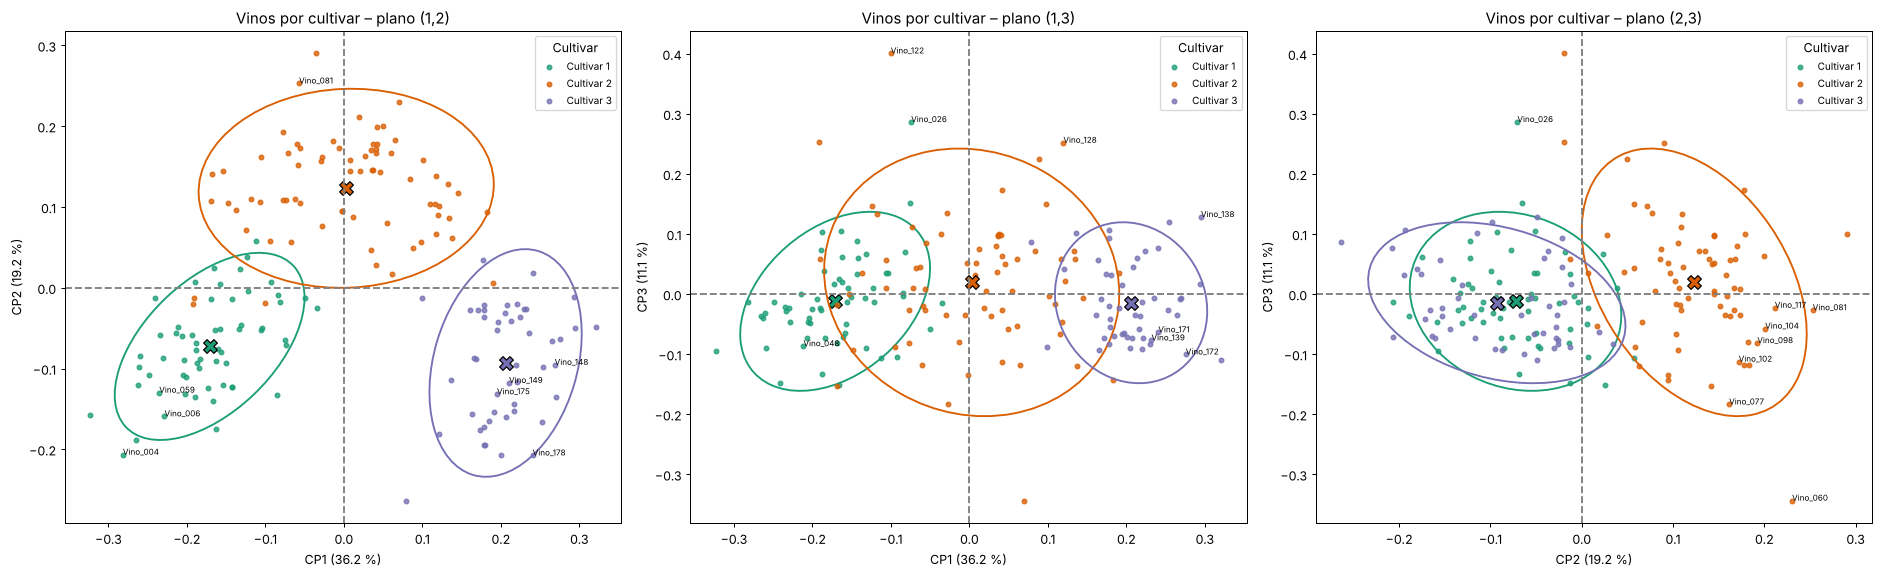

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)

# fviz_pca_ind con habillage = cultivar (con elipses por grupo), planos (1,2), (1,3) y (2,3)
def plano_ind(a, b, ax, n_etq=8):
    for g_, col in colores.items():
        ix = grupos == g_
        x, y = F.loc[ix, a], F.loc[ix, b]
        ax.scatter(x, y, s=14, color=col, label=g_, alpha=.8)
        vals, vecs = np.linalg.eigh(np.cov(x, y))
        o = vals.argsort()[::-1]; vals, vecs = vals[o], vecs[:, o]
        ang = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
        ax.add_patch(Ellipse((x.mean(), y.mean()), 2 * 2 * np.sqrt(vals[0]), 2 * 2 * np.sqrt(vals[1]),
                             angle=ang, edgecolor=col, fc="None", lw=1.5))
        ax.scatter(x.mean(), y.mean(), marker="X", s=120, color=col, edgecolor="black")
    for lab in (cos2i[a] + cos2i[b]).nlargest(n_etq).index:     # solo los mejor representados
        ax.text(F.loc[lab, a], F.loc[lab, b], lab, fontsize=6.5)
    ax.axhline(0, ls="--", color="gray"); ax.axvline(0, ls="--", color="gray")
    ax.set_xlabel(etq[a]); ax.set_ylabel(etq[b]); ax.set_title(f"Vinos por cultivar – plano ({a[2:]},{b[2:]})")
    ax.legend(title="Cultivar", fontsize=8)

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, (a, b) in zip(axes, [("CP1", "CP2"), ("CP1", "CP3"), ("CP2", "CP3")]):
    plano_ind(a, b, ax)
plt.tight_layout(); plt.show()

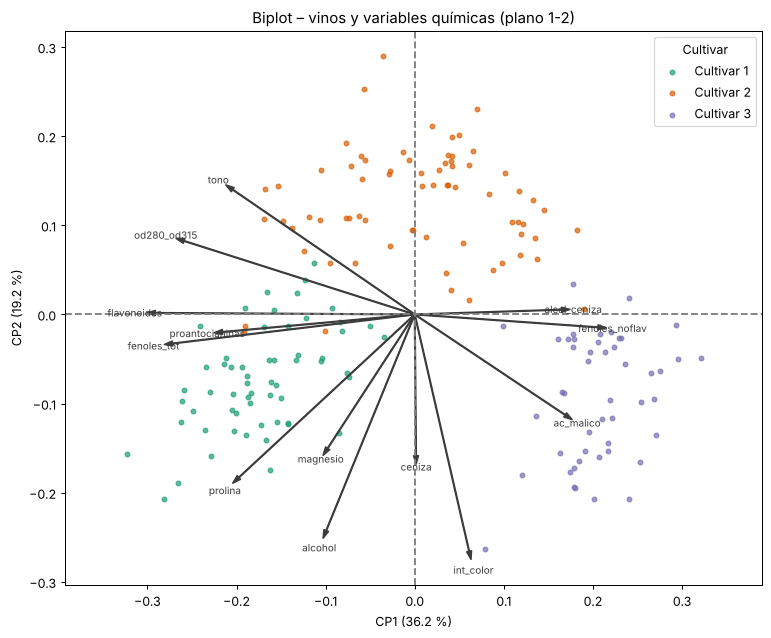

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)

# fviz_pca_biplot (plano 1-2): individuos y variables reescaladas a la misma escala
esc = np.abs(F[["CP1", "CP2"]]).max().max() / np.abs(Rcv[["CP1", "CP2"]]).max().max() * .9
fig, ax = plt.subplots(figsize=(10, 8))
for g_, col in colores.items():
    ix = grupos == g_
    ax.scatter(F.loc[ix, "CP1"], F.loc[ix, "CP2"], s=14, color=col, label=g_, alpha=.7)
for i, lab in enumerate(Rcv.index):
    x, y = Rcv["CP1"].iloc[i] * esc, Rcv["CP2"].iloc[i] * esc
    ax.arrow(0, 0, x, y, head_width=0.006, head_length=0.01, fc="#3c3c3c", ec="#3c3c3c")
    ax.text(x * 1.08, y * 1.08, lab, fontsize=8, ha="center", va="center", color="#3c3c3c")
ax.axhline(0, ls="--", color="gray"); ax.axvline(0, ls="--", color="gray")
ax.set_xlabel(etq["CP1"]); ax.set_ylabel(etq["CP2"]); ax.set_aspect("equal", adjustable="datalim")
ax.set_title("Biplot – vinos y variables químicas (plano 1-2)"); ax.legend(title="Cultivar")
plt.show()

**Lectura de los gráficos.** En el primer plano (≈ 55.4 % de la inercia) los tres cultivares forman tres nubes casi separadas en forma de arco. CP1 separa el cultivar 1 (izquierda) del cultivar 3 (derecha), y CP2 aísla al cultivar 2 (arriba). En los planos (1,3) y (2,3) la CP3 no separa los cultivares: las elipses se superponen verticalmente.

**Reflexion:** El biplot permite observar una representación simultanea de las observaciones y de las variables lo que facilita la interpretación del conjunto de datos, algo que por separado el gráfico de individuos y el círculo de correlaciones no muestran. Una limitación que al visualizar únicamente las dos primeras dimensiones, se pierde la información contenida en las componentes de orden superior.

## Punto 8. Interpretación sustantiva de las componentes

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)

# a) Tabla por componente: loadings (Q), Rcv, cos2 y ctrv
Qdf = pd.DataFrame(Q, index=X.columns, columns=F.columns)
for j in range(k):
    c = f"CP{j+1}"
    t = pd.DataFrame({"loading (Q)": Qdf[c], "Rcv": Rcv[c], "cos2": cos2v[c], "ctrv %": ctrv[c]})
    t["ctrv > 1/p"] = np.where(t["ctrv %"] > 100 / p, "✔", "")
    t["cos2 > 0.3"] = np.where(t["cos2"] > 0.3, "✔", "")
    print(f"\n===== {etq[c]} =====")
    print(t.sort_values("ctrv %", ascending=False).round(3).to_string())


===== CP1 (36.2 %) =====
                 loading (Q)    Rcv   cos2  ctrv % ctrv > 1/p cos2 > 0.3
flavonoides           -0.423 -0.917  0.842  17.887          ✔          ✔
fenoles_tot           -0.395 -0.856  0.733  15.576          ✔          ✔
od280_od315           -0.376 -0.816  0.666  14.150          ✔          ✔
proantocianinas       -0.313 -0.680  0.462   9.824          ✔          ✔
fenoles_noflav         0.299  0.648  0.419   8.912          ✔          ✔
tono                  -0.297 -0.644  0.414   8.804          ✔          ✔
prolina               -0.287 -0.622  0.387   8.223          ✔          ✔
ac_malico              0.245  0.532  0.283   6.012                      
alcal_ceniza           0.239  0.519  0.270   5.727                      
alcohol               -0.144 -0.313  0.098   2.083                      
magnesio              -0.142 -0.308  0.095   2.016                      
int_color              0.089  0.192  0.037   0.785                      
ceniza                 0.

**b) Lectura técnica de cada eje** (magnitudes grandes agrupadas por signo; *signo arbitrario*):

| Eje | Lado negativo (Rcv) | Lado positivo (Rcv) | Cultivar ubicado en cada lado |
|---|---|---|---|
| **CP1** (36.2 %) | `flavonoides` (−0.92), `fenoles_tot` (−0.86), `od280_od315` (−0.82), `proantocianinas` (−0.68), `tono` (−0.64), `prolina` (−0.62) | `fenoles_noflav` (0.65), `ac_malico` (0.53), `alcal_ceniza` (0.52) | Negativo: cultivar 1 · Positivo: cultivar 3 |
| **CP2** (19.2 %) | `int_color` (−0.84), `alcohol` (−0.76), `prolina` (−0.58), `ceniza` (−0.50), `magnesio` (−0.47) | `tono` (0.44) | Negativo: cultivares 1 y 3 · Positivo: cultivar 2 |
| **CP3** (11.1 %) | — | `ceniza` (0.75), `alcal_ceniza` (0.74) | No separa cultivares |

**CP1: 36.2 %** Eje de Riqueza Fenólica y Calidad Antioxidante; esta componente concentra más de un tercio de la variabilidad total de los datos, siendo la dimensión más importante. Mide la intensidad del perfil antioxidante y la complejidad química derivada de los compuestos fenólicos del vino. Un valor alto en este eje indica un vino con una alta concentración de compuestos fenólicos, típicamente asociado a vinos tintos de mayor cuerpo y estructura.

**CP2: 19.2 %** Eje de Perfil Cromático (Color y Tono); esta segunda componente capta casi una quinta parte de la información restante. Las variables que suelen dominar este eje son la intensidad de color y el tono, además de ciertos ácidos o componentes relacionados con la apariencia visual del vino. Un individuo ubicado en los extremos de este eje se diferencia principalmente por la vivacidad, oscuridad o matiz de su color, independientemente de su cantidad exacta de fenoles totales.

**CP3: 11.1 %** Eje de Composición Mineral y Estructural; aportando una décima parte de la variabilidad global, esta componente recoge las variables inorgánicas y de acidez básica que no alcanzaron a ser explicadas por los dos primeros ejes, tales como la alcalinidad de la ceniza, el magnesium o el contenido de ácido málico. Describe el fondo mineral y la estructura ácida básica del suelo y de la uva de origen.


## Punto 9. Proyección de las observaciones, patrones y atípicos

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)

# a) cos2 y contribuciones de los individuos
for j in range(k):
    c = f"CP{j+1}"
    print(f"\n===== {c}: 5 vinos mejor representados (cos2) =====")
    print(pd.concat([cos2i[c], F[c], datos["cultivar"]], axis=1, keys=["cos2", "coord", "cultivar"])
          .nlargest(5, "cos2").round(3).to_string())
    print(f"----- {c}: 5 vinos que más contribuyen (ctri, %) -----")
    print(pd.concat([ctri[c] * 100, F[c], datos["cultivar"]], axis=1, keys=["ctri %", "coord", "cultivar"])
          .nlargest(5, "ctri %").round(3).to_string())
print("\nReferencia: contribución promedio de un vino = 100/n =", round(100 / n, 3), "%")


===== CP1: 5 vinos mejor representados (cos2) =====
           cos2  coord    cultivar
id_vino                           
Vino_171  0.820  0.241  Cultivar 3
Vino_137  0.780  0.293  Cultivar 3
Vino_166  0.772  0.265  Cultivar 3
Vino_148  0.765  0.269  Cultivar 3
Vino_036  0.751 -0.143  Cultivar 1
----- CP1: 5 vinos que más contribuyen (ctri, %) -----
          ctri %  coord    cultivar
id_vino                            
Vino_015   2.221 -0.323  Cultivar 1
Vino_147   2.188  0.321  Cultivar 3
Vino_138   1.850  0.295  Cultivar 3
Vino_137   1.831  0.293  Cultivar 3
Vino_004   1.685 -0.282  Cultivar 1

===== CP2: 5 vinos mejor representados (cos2) =====
           cos2  coord    cultivar
id_vino                           
Vino_081  0.830  0.253  Cultivar 2
Vino_117  0.805  0.211  Cultivar 2
Vino_104  0.737  0.201  Cultivar 2
Vino_107  0.699  0.163  Cultivar 2
Vino_098  0.670  0.192  Cultivar 2
----- CP2: 5 vinos que más contribuyen (ctri, %) -----
          ctri %  coord    cultivar
id_vin

In [ ]:
# Tres observaciones concretas: perfil químico vs promedio de su cultivar
casos = ["Vino_159", "Vino_074", "Vino_122"]
perfil = pd.concat([X.loc[casos].T,
                    X.groupby(datos["cultivar"], observed=True).mean().T.add_prefix("media ")], axis=1)
print(F.loc[casos, ["CP1", "CP2", "CP3"]].join(datos["cultivar"]).round(3))
print((cos2i.loc[casos, ["CP1", "CP2", "CP3"]].sum(axis=1)).round(3).rename("cos2 en el espacio de 3 CP"))
perfil.round(2)

            CP1    CP2    CP3    cultivar
id_vino                                  
Vino_159  0.079 -0.263  0.087  Cultivar 3
Vino_074 -0.192 -0.020  0.253  Cultivar 2
Vino_122 -0.100 -0.019  0.401  Cultivar 2
id_vino
Vino_159    0.498
Vino_074    0.622
Vino_122    0.800
Name: cos2 en el espacio de 3 CP, dtype: float64


,Vino_159,Vino_074,Vino_122,media Cultivar 1,media Cultivar 2,media Cultivar 3
alcohol,14.34,12.99,11.56,13.74,12.28,13.15
ac_malico,1.68,1.67,2.05,2.01,1.93,3.33
ceniza,2.70,2.60,3.23,2.46,2.24,2.44
alcal_ceniza,25.00,30.00,28.50,17.04,20.24,21.42
magnesio,98.00,139.00,119.00,106.34,94.55,99.31
fenoles_tot,2.80,3.30,3.18,2.84,2.26,1.68
flavonoides,1.31,2.89,5.08,2.98,2.08,0.78
fenoles_noflav,0.53,0.21,0.47,0.29,0.36,0.45
proantocianinas,2.70,1.96,1.87,1.90,1.63,1.15
int_color,13.00,3.35,6.00,5.53,3.09,7.40


**Observaciones**
- **Vino_122** (cultivar 2): es el que más contribuye a CP3 (≈ 11.1 % frente al promedio de 0.56 %) y está muy bien representado en ese eje (cos2 ≈ 0.75). Tiene el máximo de la base en `ceniza` (3.23) y en `flavonoides` (5.08), y una alcalinidad de cenizas muy alta (28.5 frente a 20.2 de su cultivar). Por eso queda arriba del todo en el plano (1,3). También es el mayor atípico en ambas estadísticas del literal d).
- **Vino_159** (cultivar 3): segundo mayor contribuyente a CP2 (≈ 2.8 %), con coordenada muy negativa en ese eje. Tiene la máxima intensidad de color de la base (13.0) y más alcohol (14.3) que el promedio de su cultivar (13.2). Es una versión "extrema" del perfil alcohol–color.
- **Vino_074** (cultivar 2): tiene la alcalinidad de cenizas máxima (30.0) y magnesio alto (139 frente a 94.6 de su cultivar). Contribuye ≈ 4.4 % a CP3 y está entre los atípicos por $d^2_{1i}$. Aunque es del cultivar 2, en el plano (1,2) queda lejos del centro de su grupo.

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)

# c) Indicadores en [0,1] a partir de las k primeras componentes (función del profesor)
acp = PCA(n_components=k).fit(X_scaled)

def indicadores(acp, k, alpha=3):
    f = pd.DataFrame(acp.transform(X_scaled)[:, :k], index=datos.index)
    for j in range(k):
        Q1, Q3 = f.iloc[:, j].quantile([0.25, 0.75])
        RIC = Q3 - Q1
        a = min(f.iloc[:, j].min(), Q1 - alpha * RIC)
        b = max(Q3 + alpha * RIC, f.iloc[:, j].max())
        f.iloc[:, j] = (f.iloc[:, j] - a) / (b - a)
    f.columns = [f"I{i+1}" for i in range(k)]
    return f

I = indicadores(acp, k=k)
print("Signo de CP1 en sklearn vs DVS a mano:", int(np.sign(np.corrcoef(I["I1"], F["CP1"])[0, 1])))
print("\n5 vinos con menor I1:"); print(I.join(datos["cultivar"]).nsmallest(5, "I1").round(3))
print("\n5 vinos con mayor I1:"); print(I.join(datos["cultivar"]).nlargest(5, "I1").round(3))

Signo de CP1 en sklearn vs DVS a mano: -1

5 vinos con menor I1:
             I1     I2     I3    cultivar
id_vino                                  
Vino_147  0.356  0.540  0.372  Cultivar 3
Vino_138  0.368  0.540  0.657  Cultivar 3
Vino_137  0.369  0.513  0.523  Cultivar 3
Vino_172  0.377  0.550  0.383  Cultivar 3
Vino_156  0.380  0.602  0.495  Cultivar 3

5 vinos con mayor I1:
             I1     I2     I3    cultivar
id_vino                                  
Vino_015  0.651  0.618  0.390  Cultivar 1
Vino_004  0.632  0.654  0.487  Cultivar 1
Vino_019  0.624  0.641  0.460  Cultivar 1
Vino_053  0.623  0.592  0.456  Cultivar 1
Vino_011  0.622  0.575  0.465  Cultivar 1


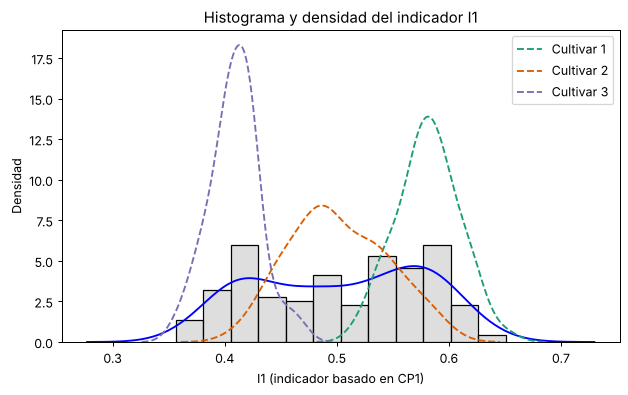

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)

# Distribución del primer indicador
plt.figure(figsize=(8, 4.5))
sns.histplot(I["I1"], bins=12, stat="density", color="lightgray", edgecolor="black")
sns.kdeplot(I["I1"], color="blue")
for g_, col in colores.items():
    sns.kdeplot(I.loc[grupos == g_, "I1"], color=col, ls="--", label=g_)
plt.xlabel("I1 (indicador basado en CP1)"); plt.ylabel("Densidad")
plt.title("Histograma y densidad del indicador I1"); plt.legend(); plt.show()

**Interpretación.** $I_1$ reescala la CP1 al intervalo [0,1] usando cuartiles y 3·RIC, de modo que un vino extremo no fija por sí solo los límites. Por eso los valores observados quedan entre ≈ 0.36 y 0.65 y no ocupan todo el intervalo. El signo de la CP1 en `sklearn` es **opuesto** al de la DVS a mano, así que en $I_1$ los valores altos corresponden al lado fenólico. Los 5 máximos son todos del cultivar 1 (Vino_015, 004, 019, 053, 011) y los 5 mínimos son todos del cultivar 3 (Vino_147, 138, 137, 172, 156). La densidad global es ancha y casi plana porque mezcla tres grupos: cada cultivar forma su propio modo (cultivar 3 ≈ 0.41, cultivar 2 ≈ 0.49, cultivar 1 ≈ 0.58), y el cultivar 2 se traslapa con los otros dos.

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)

# d) Atípicos: estadísticas d1i^2 (primeras componentes) y d2i^2 (últimas componentes)
acp_full = PCA(n_components=X.shape[1]).fit(X_scaled)

def d12(acp, p1, alpha=0.05):
    F_ = acp.transform(X_scaled)
    F1 = (F_ - F_.mean(axis=0)) / F_.std(axis=0, ddof=1)
    d1i2 = np.sum(F1[:, :p1]**2, axis=1)
    cuantil = np.quantile(d1i2, 1 - alpha)
    return pd.DataFrame({"Observación": np.arange(1, F_.shape[0] + 1), "d12": d1i2,
                         "Cuantil": cuantil, "Atípico": d1i2 > cuantil}, index=datos.index)

def d22(acp, q, alpha=0.05):
    F_ = acp.transform(X_scaled)
    F1 = (F_ - F_.mean(axis=0)) / F_.std(axis=0, ddof=1)
    p_ = F_.shape[1]
    d2i2 = np.sum(F1[:, p_ - q:p_]**2, axis=1)
    cuantil = np.quantile(d2i2, 1 - alpha)
    return pd.DataFrame({"Observación": np.arange(1, F_.shape[0] + 1), "d22": d2i2,
                         "Cuantil": cuantil, "Atípico": d2i2 > cuantil}, index=datos.index)

p1, q = k, 2          # p1 = componentes retenidas; q = 2 últimas componentes (λ12, λ13 < 0.2)
est_d12 = d12(acp_full, p1=p1, alpha=0.05)
est_d22 = d22(acp_full, q=q, alpha=0.05)
print("Atípicos según d1i^2 (primeras", p1, "componentes):")
print(est_d12[est_d12["Atípico"]].join(datos["cultivar"]).round(3))
print("\nAtípicos según d2i^2 (últimas", q, "componentes):")
print(est_d22[est_d22["Atípico"]].join(datos["cultivar"]).round(3))
ambos = est_d12.index[est_d12["Atípico"] & est_d22["Atípico"]]
print("\nDetectados por ambas:", list(ambos))

Atípicos según d1i^2 (primeras 3 componentes):
          Observación     d12  Cuantil  Atípico    cultivar
id_vino                                                    
Vino_015           15   6.778    6.037     True  Cultivar 1
Vino_026           26  10.599    6.037     True  Cultivar 1
Vino_060           60  18.400    6.037     True  Cultivar 2
Vino_074           74   9.244    6.037     True  Cultivar 2
Vino_116          116   7.262    6.037     True  Cultivar 2
Vino_122          122  20.051    6.037     True  Cultivar 2
Vino_123          123   6.699    6.037     True  Cultivar 2
Vino_128          128   8.889    6.037     True  Cultivar 2
Vino_159          159   6.078    6.037     True  Cultivar 3

Atípicos según d2i^2 (últimas 2 componentes):
          Observación     d22  Cuantil  Atípico    cultivar
id_vino                                                    
Vino_068           68   7.126    6.185     True  Cultivar 2
Vino_069           69   6.688    6.185     True  Cultivar 2
Vino_0

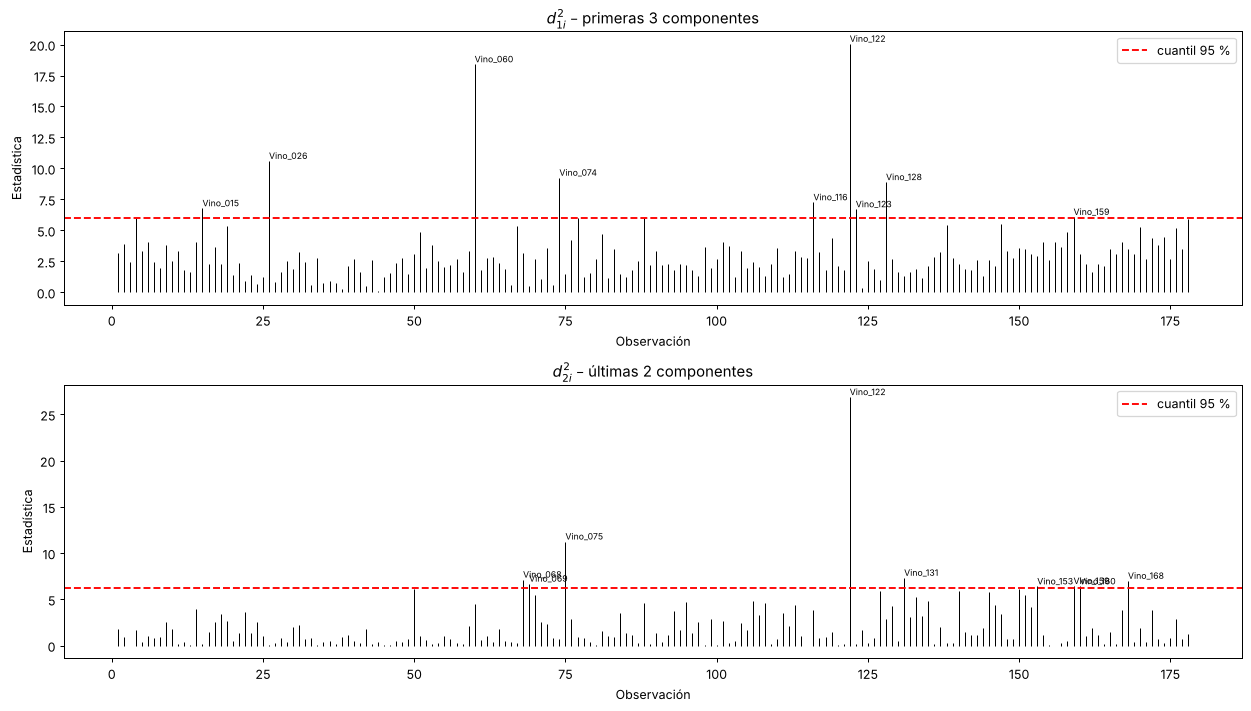

In [ ]:
# Adaptado de: Pacheco (repositorio multivariate)
# Gráficos de las estadísticas
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, est, col, tit in [(axes[0], est_d12, "d12", f"$d^2_{{1i}}$ – primeras {p1} componentes"),
                          (axes[1], est_d22, "d22", f"$d^2_{{2i}}$ – últimas {q} componentes")]:
    ax.vlines(est["Observación"], 0, est[col], color="black", lw=.8)
    ax.axhline(est["Cuantil"].iloc[0], ls="--", color="red", label="cuantil 95 %")
    for i in np.where(est["Atípico"])[0]:
        ax.text(est["Observación"].iloc[i], est[col].iloc[i], est.index[i], fontsize=7, va="bottom")
    ax.set_ylabel("Estadística"); ax.set_xlabel("Observación"); ax.set_title(tit); ax.legend()
plt.tight_layout(); plt.show()

**Diferencia entre las dos estadísticas.** Con $\alpha = 0.05$ y el cuantil empírico, cada estadística marca 9 vinos (≈ 5 % de 178). Solo **Vino_122** y **Vino_159** aparecen en ambas. Los atípicos de $d^2_{1i}$ son casi todos del cultivar 2 y coinciden con los mayores contribuyentes a CP2/CP3 (Vino_060, 122, 026, 074, 116). Los de $d^2_{2i}$ son en su mayoría distintos (Vino_075, 068, 069, 131, 168…).
- $d^2_{1i}$ ($p_1 = 3$) mide qué tan lejos está un vino del centro **dentro del subespacio retenido**. Detecta vinos con valores extremos en las direcciones principales (por ejemplo, mucho color/alcohol o mucha ceniza), es decir, versiones "exageradas" del patrón general. Estos atípicos pueden inflar la varianza de las primeras componentes.
- $d^2_{2i}$ ($q = 2$, componentes con $\lambda \approx 0.17$ y $0.10$) mide la distancia en las direcciones donde casi no hay variabilidad. Detecta vinos que **rompen la estructura de correlación**: combinaciones de variables inusuales (por ejemplo, muchos fenoles totales pero pocos flavonoides) aunque cada valor por separado sea normal. Son invisibles en el primer plano.

**Reflexion:** Los valores atípicos en la base de datos pueden distorsionar la información ocasionando que los resultados del ACP sean incorrectos, esto se debe a que la varianza y covarianza son sensibles a los datos. Lo que podría ocasionar una predominación sobre dichos valores haciendo no correcta la interpretación de la información.

## Punto 10. Conclusiones y limitaciones

**a) Respuesta a la pregunta de investigación**

Las 13 mediciones químicas originales se lograron reducir eficientemente en tres componentes principales que retienen el 66.5 % de la inercia total (CP1: 36.2 %, CP2: 19.2 %, y CP3: 11.1%). Estas dimensiones tienen un sentido químico claro y coherente con la conjetura inicial: CP1 representa la Riqueza Fenólica y Calidad Antioxidante; CP2 representa el Perfil Cromático (Color y Tono); CP3 representa la Composición Mineral y Estructural. Al proyectar las observaciones en este nuevo espacio reducido (especialmente en el plano factorial de CP1 y CP2), se observa que los tres cultivares de uva se separan y agrupan de manera clara y distinguible. Esto demuestra que las diferencias químicas intrínsecas de cada variedad de uva no están dispersas al azar, sino que se concentran precisamente en estas dimensiones latentes (lideradas por la riqueza fenólica y el color), validando la efectividad del Análisis de Componentes Principales como herramienta de clasificación y reducción de dimensionalidad para este conjunto de datos.

In [ ]:
# Codigo propio
# b) Información perdida con k componentes
print(f"Inercia retenida con k = {k}: {inercia_acum[k-1]:.1f} %")
print(f"Información perdida: {100 - inercia_acum[k-1]:.1f} %")

Inercia retenida con k = 3: 66.5 %
Información perdida: 33.5 %


**b)** Con $k = 3$ se retiene ≈ 66.5 % de la inercia y se pierde ≈ **33.5 %**. La pérdida es aceptable para el objetivo: las 10 componentes descartadas tienen $\lambda < 1$ (cada una explica menos que una variable original), y la separación de los cultivares ya se logra en el primer plano. Si el objetivo fuera reconstruir con precisión cada medición química, la pérdida sería alta y convendría retener 5 componentes (≈ 80 %).

**c) Limitaciones.**
1. **Linealidad.** El ACP solo captura relaciones lineales. Las variables asimétricas (`prolina`, `ac_malico`, `magnesio`, `int_color`) generan nubes en abanico que la correlación de Pearson resume solo de forma parcial.
2. **Sensibilidad a atípicos y a la escala.** Unos pocos vinos extremos (p. ej., Vino_122, con el máximo de cenizas y flavonoides, que aporta 11 % de la inercia de CP3) influyen en las correlaciones y en la dirección de los ejes. Además, el resultado depende de haber estandarizado: con la matriz de covarianzas, `prolina` dominaría el ACP.
3. **Signo arbitrario de los ejes.** El sentido de cada componente lo decide el algoritmo (DVS vs. `eigh` vs. `sklearn`). Al construir el indicador $I_1$ hay que verificar el signo antes de decir "más alto = más fenólico".
4. **Ejes con poca inercia.** La CP3 (≈ 11 %) depende casi solo de dos variables (`ceniza`, `alcal_ceniza`), por lo que su interpretación es menos robusta. La CP4 quedó por fuera aunque está cerca del umbral.
5. **Representatividad.** Son 178 vinos de una sola región italiana y de tres cultivares, analizados hace más de 30 años. Las conclusiones no se generalizan a otras regiones, añadas o variedades.

**d) Trabajo futuro.**
- Comparar con un **ACP robusto** (MCD o *projection pursuit*, ya incluidos en el código del profesor) para medir cuánto cambian los ejes sin los atípicos detectados.
- Usar **análisis discriminante lineal** con el cultivar como respuesta, para pasar de "describir" a "clasificar" y evaluar si las 3 componentes bastan para predecir la variedad.
- Ampliar con datos de **Wine Quality** (UCI, vinhos verdes de Portugal) o agregar variables sensoriales (puntaje de catadores), para relacionar los ejes químicos con la calidad percibida.